In [14]:
!pip install pydot graphviz


In [15]:
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import Markdown
import pandas as pd

In [16]:
# Load Dataset
dataset = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test)= dataset.load_data()

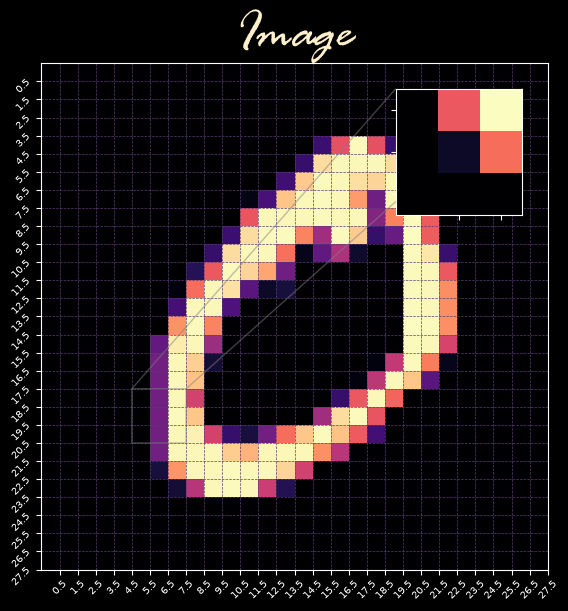

In [ ]:
fig, ax = plt.subplots(1,2, figsize= (12,6), layout='constrained')
fig.set_edgecolor('none')
plt.style.use('dark_background')
title_font = {'family': 'Rage Italic', 'color': "#fff0cc", 'weight': "normal", 'size': 40}

ax[0].grid(axis ='both', color="#593D74", linestyle='--',linewidth = .5,)
ax[0].set_title("Image",fontdict = title_font)
ax[0].imshow(x_train[1], cmap='magma',origin="upper")


zoom_ax = ax[0].inset_axes([0.7,0.7,.25,.25], xlim = (4.5,7.5), ylim = (17.5,20.5), xticklabels=[], yticklabels=[])
ax[0].indicate_inset_zoom(zoom_ax)
zoom_ax.imshow(x_train[10],cmap='magma',origin="upper")

ticks = list(map(lambda x: sum([x,0.5]),range(0,28,1)))
ax[0].set_yticks(ticks)
ax[0].set_xticks(ticks)
ax[0].tick_params(labelsize = 7,rotation=45)

ax[1].set_title("Probablities",fontdict = title_font)
ax[1].set_xticks(range(10))
ax[1].set_visible(False)
ax[1].
plt.show()

In [18]:
model = tf.keras.models.Sequential([
            tf.keras.layers.Input((28,28)),
            tf.keras.layers.Flatten(),
            tf.keras.layers.Dense(128,activation=tf.keras.activations.sigmoid),
            tf.keras.layers.Dense(10)
            ])
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)



In [56]:
import math

def get_color(value, data_min, data_max, color_list, list_len):
    if data_max == data_min:
        return color_list[0] 
    
    index = math.floor(((value - data_min) / (data_max - data_min)) * list_len)
    
    index = max(0, min(255, index))
    
    return color_list[index]


In [81]:
def display_fig(X, probab_result, zoom_loc: list|tuple|None = None):
    magma = plt.get_cmap('magma')
    mapped_colors = list(map(lambda x: get_color(x,
                        -.3, max(probab_result), magma.colors,
                        len(magma.colors)-1), probab_result)) # pyright: ignore[reportAttributeAccessIssue]

    df_metrics = pd.DataFrame({
        'Class': range(10),
        'Probability': probab_result
    })

    df_metrics['Probability'] = df_metrics['Probability'].map('{:.4%}'.format) # Displays as percentages

    ax[1].cla()

    ax[0].imshow(X, cmap="magma")
    zoom_ax.imshow(X,cmap='magma',origin="upper")
    if zoom_loc:
        zoom_ax.set_xlim(zoom_loc[:2])
        zoom_ax.set_ylim(zoom_loc[2:])

    bar_chart = ax[1].bar(range(10),probab_result,color = mapped_colors,edgecolor='none',width=.5)
    ax[1].set_visible(True)
    ax[1].bar_label(bar_chart, padding=3, fmt=lambda x: f"{x:.2f}")
    
    display(fig)

    display(Markdown("## Model Analysis Metrics"))
    display(Markdown(f"### Loss Value &rarr; `{loss:.4f}`"))
    display(Markdown("### Predictions & Class Probabilities"))
    display(Markdown(df_metrics.to_markdown(index=False)))

# **Before Training**

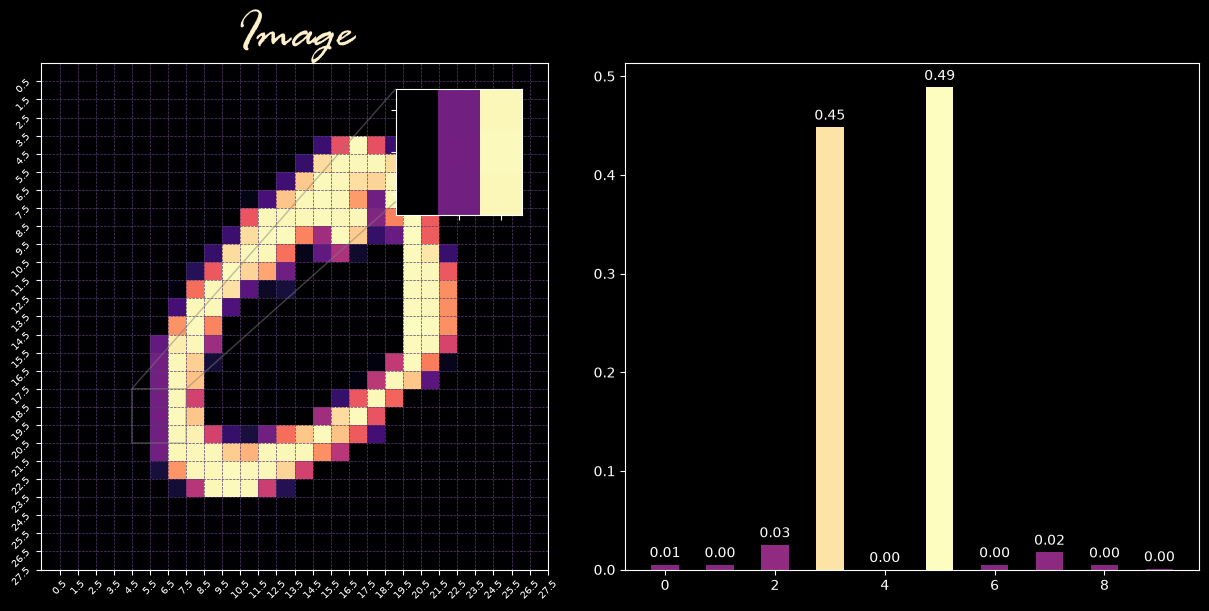

## Model Analysis Metrics

### Loss Value &rarr; `0.7163`

### Predictions & Class Probabilities

|   Class | Probability   |
|--------:|:--------------|
|       0 | 0.5080%       |
|       1 | 0.4900%       |
|       2 | 2.5139%       |
|       3 | 44.8343%      |
|       4 | 0.0007%       |
|       5 | 48.8573%      |
|       6 | 0.4886%       |
|       7 | 1.7573%       |
|       8 | 0.4690%       |
|       9 | 0.0810%       |

In [82]:
model.compile(optimizer="adam", loss=loss_fn)
pred = model(x_train[:1]).numpy()
loss = loss_fn(y_train[:1], pred).numpy()
probab_result = tf.nn.softmax(pred).numpy()
display_fig(x_train[1], probab_result[0])


# **After Training**

In [22]:
trained_model = tf.keras.Sequential([model])
trained_model.compile(optimizer="adam", loss = loss_fn, metrics=['accuracy'])
trained_model.fit(x_train, y_train, epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8593 - loss: 0.5159
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8989 - loss: 0.3522
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9015 - loss: 0.3332
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9066 - loss: 0.3154
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9114 - loss: 0.2951
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9164 - loss: 0.2788
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9224 - loss: 0.2605
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9238 - loss: 0.2517
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9247 - loss: 0.2476
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9245 - loss: 0.2486


In [23]:
untrained_mode_eval = model.evaluate(x_test, y_test)
trained_model_eval = trained_model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2662
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9171 - loss: 0.2662


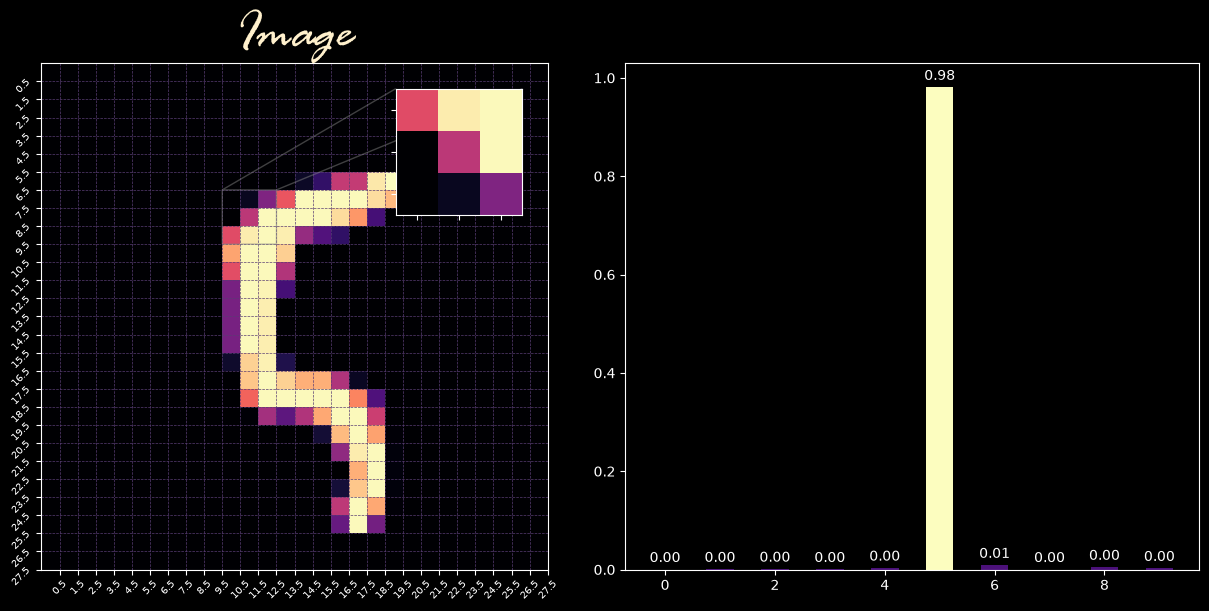

## Model Analysis Metrics

### Loss Value &rarr; `0.7163`

### Predictions & Class Probabilities

|   Class | Probability   |
|--------:|:--------------|
|       0 | 0.0040%       |
|       1 | 0.0386%       |
|       2 | 0.0747%       |
|       3 | 0.0140%       |
|       4 | 0.2903%       |
|       5 | 98.0554%      |
|       6 | 0.8489%       |
|       7 | 0.0006%       |
|       8 | 0.4493%       |
|       9 | 0.2241%       |

In [87]:
probab_model = tf.keras.Sequential([
                trained_model,
                tf.keras.layers.Softmax()
                ])

chekcker = 100

trained_probab_result = probab_model(x_train[:chekcker+1]).numpy()
display_fig(x_train[chekcker], trained_probab_result[-1],[9.5, 12.5, 6.5, 9.5])

In [88]:
trained_model.save("Model.keras")

# Available Fonts

In [25]:
import matplotlib.font_manager as fm

# Get a sorted list of all available font names
available_fonts = sorted(set([f.name for f in fm.fontManager.ttflist]))

# Print the first 20 fonts found
for font in available_fonts:
    print(font)

AIGDT
AMGDT
AcadEref
Agency FB
Algerian
AmdtSymbols
Aparajita
Arial
Arial Black
Arial Narrow
Arial Rounded MT Bold
Arial Unicode MS
Artifakt Element
Artifakt Element Black
Artifakt Element Book
Artifakt Element Hair
Artifakt Element Heavy
Artifakt Element Light
Artifakt Element Medium
Artifakt Element Thin
Bahnschrift
BankGothic Lt BT
BankGothic Md BT
Baskerville Old Face
Bauhaus 93
Bell MT
Berlin Sans FB
Berlin Sans FB Demi
Bernard MT Condensed
Blackadder ITC
Bodoni MT
Bodoni MT Black
Bodoni MT Condensed
Bodoni MT Poster Compressed
Book Antiqua
Bookman Old Style
Bookshelf Symbol 7
Bradley Hand ITC
Britannic Bold
Broadway
Brush Script MT
Calibri
Calibri Light
Californian FB
Calisto MT
Cambria
Cambria Math
Candara
Candara Light
Cascadia Code
Cascadia Mono
Castellar
Centaur
Century
Century Gothic
Century Schoolbook
Chiller
CityBlueprint
Colonna MT
Comic Sans MS
CommercialPi BT
CommercialScript
CommercialScript BT
Complex
Consolas
Constantia
Cooper Black
Copperplate Gothic Bold
Copperplat